In [13]:
!pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [15]:
import os

print("Current Working Directory:")
print(os.getcwd())

Current Working Directory:
C:\Users\DELL\OneDrive\Documents\SQL_Practice


In [16]:
print(os.listdir())

['.ipynb_checkpoints', '50_Startups.csv', 'day1.sql', 'day11.ipynb', 'Day13.ipynb', 'Day14_Machine_Learning.ipynb', 'Day9.sql', 'practice.db', 'startup_analysis.db']


In [17]:
data = pd.read_csv("C:/Users/DELL/OneDrive/Documents/SQL_Practice/50_Startups.csv"
)

print("Dataset Loaded Successfully!")

data.head()

Dataset Loaded Successfully!


,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [18]:
import pandas as pd

url = "https://raw.githubusercontent.com/plotly/datasets/master/50_Startups.csv"

data = pd.read_csv(url)

print("Dataset Loaded Successfully!")

HTTPError: HTTP Error 404: Not Found

In [19]:
print("Dataset Shape:", data.shape)

print("\nDataset Information:")
data.info()

Dataset Shape: (50, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     str    
 4   Profit           50 non-null     float64
dtypes: float64(4), str(1)
memory usage: 2.5 KB


In [20]:
print("Missing Values:")
print(data.isnull().sum())

Missing Values:
R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64


In [21]:
data.describe()

,R&D Spend,Administration,Marketing Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [23]:
X = data.drop("Profit", axis=1)
y = data["Profit"]

print("X and y Created Successfully!")

X and y Created Successfully!


In [24]:
X_encoded = pd.get_dummies(
    X,
    columns=["State"],
    drop_first=True,
    dtype=int
)

print("Encoding Completed Successfully!")
display(X_encoded.head())

print("Encoded Shape:", X_encoded.shape)

Encoding Completed Successfully!


,R&D Spend,Administration,Marketing Spend,State_Florida,State_New York
0,165349.20,136897.80,471784.10,0,1
1,162597.70,151377.59,443898.53,0,0
2,153441.51,101145.55,407934.54,1,0
3,144372.41,118671.85,383199.62,0,1
4,142107.34,91391.77,366168.42,1,0


Encoded Shape: (50, 5)


In [27]:
# First split: 70% Training and 30% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X_encoded,
    y,
    test_size=0.30,
    random_state=42
)

# Second split: 15% Validation and 15% Testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)


Training Data: (35, 5)
Validation Data: (7, 5)
Testing Data: (8, 5)


In [28]:
# Create Linear Regression Model
model = LinearRegression()

# Train the Model
model.fit(X_train, y_train)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [29]:
# Predict Profit
val_predictions = model.predict(X_val)

print("Actual Profit:")
print(y_val.values)

print("\nPredicted Profit:")
print(val_predictions)

Actual Profit:
[182901.99 125370.37 107404.34 141585.52  89949.14  64926.08 105733.54]

Predicted Profit:
[172313.87139381 127062.20722787 100600.61123707 128818.49200667
  93736.28538393  45706.12238325 109114.62977498]


In [30]:
# Calculate Evaluation Metrics

val_mae = mean_absolute_error(y_val, val_predictions)

val_mse = mean_squared_error(y_val, val_predictions)

val_rmse = np.sqrt(val_mse)

val_r2 = r2_score(y_val, val_predictions)

print("Validation MAE:", round(val_mae, 2))
print("Validation MSE:", round(val_mse, 2))
print("Validation RMSE:", round(val_rmse, 2))
print("Validation R2 Score:", round(val_r2, 4))

Validation MAE: 8319.84
Validation MSE: 102777043.81
Validation RMSE: 10137.9
Validation R2 Score: 0.9171


In [31]:
# Predict Profit using Test Data

test_predictions = model.predict(X_test)

print("Actual Profit:")
print(y_test.values)

print("\nPredicted Profit:")
print(test_predictions)

Actual Profit:
[122776.86 166187.94 134307.35 152211.77  35673.41  97427.84  99937.59
  81005.76]

Predicted Profit:
[111730.57706801 174195.35772603 126187.39411512 148381.04097174
  51891.83884402  97953.99874703  99777.0281516   85788.82259489]


In [32]:
# Calculate Test Metrics

mae = mean_absolute_error(y_test, test_predictions)

mse = mean_squared_error(y_test, test_predictions)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, test_predictions)

print("Final Model Evaluation")
print("----------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Final Model Evaluation
----------------------
MAE: 6586.57
MSE: 69120627.35
RMSE: 8313.88
R2 Score: 0.9551


In [33]:
results = pd.DataFrame({
    "Actual Profit": y_test.values,
    "Predicted Profit": test_predictions
})

display(results)

,Actual Profit,Predicted Profit
0,122776.86,111730.577068
1,166187.94,174195.357726
2,134307.35,126187.394115
3,152211.77,148381.040972
4,35673.41,51891.838844
5,97427.84,97953.998747
6,99937.59,99777.028152
7,81005.76,85788.822595


In [34]:
results = pd.DataFrame({
    "Actual Profit": y_test.values,
    "Predicted Profit": test_predictions
})

display(results)

,Actual Profit,Predicted Profit
0,122776.86,111730.577068
1,166187.94,174195.357726
2,134307.35,126187.394115
3,152211.77,148381.040972
4,35673.41,51891.838844
5,97427.84,97953.998747
6,99937.59,99777.028152
7,81005.76,85788.822595


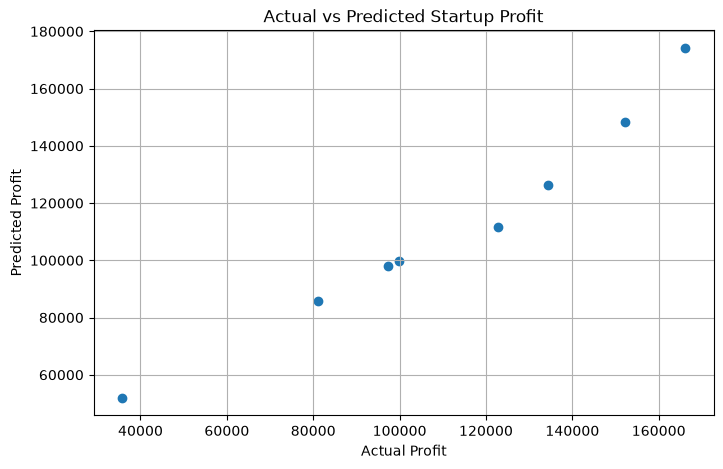

In [35]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, test_predictions)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")

plt.title("Actual vs Predicted Startup Profit")

plt.grid(True)

plt.show()

In [36]:
print("MACHINE LEARNING MODEL SUMMARY")
print("--------------------------------")

print("Algorithm: Linear Regression")
print("Dataset: 50_Startups.csv")
print("Target Variable: Profit")

print("Training Rows:", len(X_train))
print("Validation Rows:", len(X_val))
print("Testing Rows:", len(X_test))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MACHINE LEARNING MODEL SUMMARY
--------------------------------
Algorithm: Linear Regression
Dataset: 50_Startups.csv
Target Variable: Profit
Training Rows: 35
Validation Rows: 7
Testing Rows: 8
MAE: 6586.57
RMSE: 8313.88
R2 Score: 0.9551


In [37]:
# Training Predictions
train_predictions = model.predict(X_train)

# Training R2 Score
train_r2 = r2_score(y_train, train_predictions)

# Testing R2 Score
test_r2 = r2_score(y_test, test_predictions)

print("Training R2 Score:", round(train_r2, 4))
print("Testing R2 Score:", round(test_r2, 4))

Training R2 Score: 0.9511
Testing R2 Score: 0.9551


In [38]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

# Load Dataset
iris = load_iris()

X_iris = iris.data
y_iris = iris.target

# Split Dataset
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris,
    y_iris,
    test_size=0.20,
    random_state=42,
    stratify=y_iris
)

# Train Classification Model
classifier = LogisticRegression(max_iter=200)

classifier.fit(X_train_iris, y_train_iris)

# Make Predictions
iris_predictions = classifier.predict(X_test_iris)

print("Classification Model Trained Successfully!")

Classification Model Trained Successfully!


In [39]:
print("Accuracy:", accuracy_score(y_test_iris, iris_predictions))

print("Precision:", precision_score(
    y_test_iris, iris_predictions, average="weighted"
))

print("Recall:", recall_score(
    y_test_iris, iris_predictions, average="weighted"
))

print("F1 Score:", f1_score(
    y_test_iris, iris_predictions, average="weighted"
))

Accuracy: 0.9666666666666667
Precision: 0.9696969696969696
Recall: 0.9666666666666667
F1 Score: 0.9665831244778613


In [40]:
classification_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [
        accuracy_score(y_test_iris, iris_predictions),
        precision_score(y_test_iris, iris_predictions, average="weighted"),
        recall_score(y_test_iris, iris_predictions, average="weighted"),
        f1_score(y_test_iris, iris_predictions, average="weighted")
    ]
})

display(classification_results)

,Metric,Score
0,Accuracy,0.966667
1,Precision,0.969697
2,Recall,0.966667
3,F1 Score,0.966583


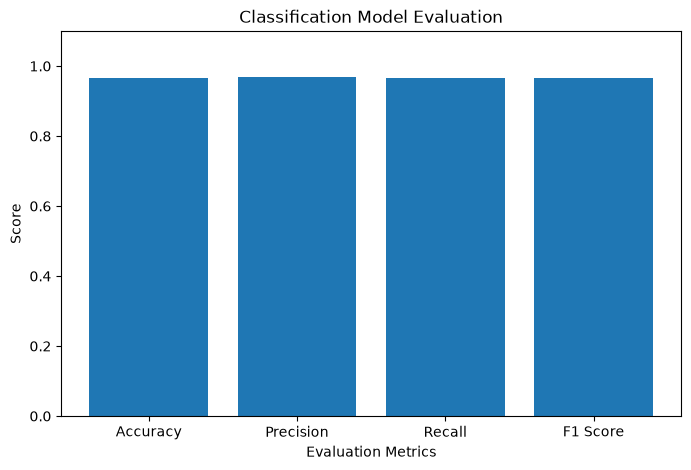

In [41]:
plt.figure(figsize=(8, 5))

plt.bar(
    classification_results["Metric"],
    classification_results["Score"]
)

plt.title("Classification Model Evaluation")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.1)

plt.show()

In [42]:
classification_results.to_csv(
    "classification_evaluation_results.csv",
    index=False
)

print("Results Saved Successfully!")

Results Saved Successfully!


In [43]:
regression_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Score": [mae, mse, rmse, r2]
})

regression_results.to_csv(
    "regression_evaluation_results.csv",
    index=False
)

print("Regression Results Saved Successfully!")

Regression Results Saved Successfully!
